In [38]:
from pathlib import Path
from astropy.io import fits
from astropy.stats import sigma_clipped_stats

import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from skimage.transform import resize

## Calculate RMS of all fits files

In [39]:

# Directory containing FITS files
final_dir = Path("/scratch/gsc9zr/Machine-Learning-Project/Astromorph_project/alma_TAP/final_fits_file")

# Find all pbcor FITS files
pbcor_files = sorted(final_dir.glob("*pbcor*.fits"))

print("Total FITS files:", len(pbcor_files))

# Dictionary to store RMS values
rms_values = {}

# Calculate RMS for each cube
for f in pbcor_files:

    data = fits.getdata(f)
    data = np.squeeze(data)

    # Select emission-free channels (example)
    noise_data = data[0:10, :, :]

    # Calculate RMS
    rms = np.sqrt(np.nanmean(noise_data**2))

    # Store RMS for each FITS file
    rms_values[f.name] = rms

    # Extract source name
    source_name = f.name.split(".")[2].split("_sci")[0]

    print(f"Source: {source_name}, RMS: {rms:.6f}")

Total FITS files: 31
Source: ari_l, RMS: 0.036330
Source: ari_l, RMS: 0.032260
Source: W42-MME, RMS: 0.003464
Source: Lh01, RMS: 0.016631
Source: Lh03, RMS: 0.017104
Source: Lh04, RMS: 0.017281
Source: Lh05, RMS: 0.016640
Source: Lh06, RMS: 0.016471
Source: Lh08, RMS: 0.016815
Source: Lh09, RMS: 0.016234
Source: Ll10, RMS: 0.016817
Source: Lm04, RMS: 0.016766
Source: Lm05, RMS: 0.017034
Source: Lm07, RMS: 0.016760
Source: Lm10, RMS: 0.016379
Source: S01, RMS: 0.009930
Source: S02, RMS: 0.010102
Source: S03, RMS: 0.009713
Source: S04, RMS: 0.009419
Source: S05, RMS: 0.009854
Source: S06, RMS: 0.009922
Source: S07, RMS: 0.009564
Source: S08, RMS: 0.009409
Source: S09, RMS: 0.009868
Source: S10, RMS: 0.009923
Source: HH_211, RMS: 0.003321
Source: _G206, RMS: 0.002062
Source: _G210, RMS: 0.002729
Source: 08303-4303, RMS: 0.010749
Source: 10295-5746, RMS: 0.011073
Source: 10365-5803, RMS: 0.008678


## check the original size of all fits files

In [40]:

for f in pbcor_files:

    data = fits.getdata(f)
    data = np.squeeze(data)

    print(f.name, data.shape)

member.uid___A001_X122_X4a1.ari_l.IRAS_16293-2422_sci.spw0_347327MHz.12m.cube.I.pbcor.fits (958, 1050, 1050)
member.uid___A001_X122_X4a3.ari_l.IRAS_16293-2422_sci.spw0_347327MHz.12m.cube.I.pbcor.fits (958, 240, 240)
member.uid___A001_X133d_X3b81.W42-MME_sci.spw25.cube.I.pbcor.fits (1918, 588, 588)
member.uid___A001_X1465_X1bc.Lh01_sci.spw29.cube.I.pbcor.fits (3837, 480, 480)
member.uid___A001_X1465_X1bc.Lh03_sci.spw29.cube.I.pbcor.fits (3837, 480, 480)
member.uid___A001_X1465_X1bc.Lh04_sci.spw29.cube.I.pbcor.fits (3837, 480, 480)
member.uid___A001_X1465_X1bc.Lh05_sci.spw29.cube.I.pbcor.fits (3837, 480, 480)
member.uid___A001_X1465_X1bc.Lh06_sci.spw29.cube.I.pbcor.fits (3837, 480, 480)
member.uid___A001_X1465_X1bc.Lh08_sci.spw29.cube.I.pbcor.fits (3837, 480, 480)
member.uid___A001_X1465_X1bc.Lh09_sci.spw29.cube.I.pbcor.fits (3837, 480, 480)
member.uid___A001_X1465_X1bc.Ll10_sci.spw29.cube.I.pbcor.fits (3837, 480, 480)
member.uid___A001_X1465_X1bc.Lm04_sci.spw29.cube.I.pbcor.fits (3837, 

## build Moment 8 maps

In [41]:

# Dictionary to store moment-8 maps
moment8_maps = {}

for f in pbcor_files:

    with fits.open(f, memmap=True) as hdul:

        data = np.squeeze(hdul[0].data)

        # Check that data is a 3D cube
        if data.ndim != 3:
            print("Skipping:", f.name)
            continue

        # Generate moment-8 map
        moment8 = np.nanmax(data, axis=0)

        # Store moment-8 map
        moment8_maps[f.name] = moment8

        # Extract source name
        source_name = f.name.split(".")[2].split("_sci")[0]

        print(source_name, moment8.shape)

print("Total moment-8 maps:", len(moment8_maps))

/tmp/ipykernel_391588/1737931706.py:16: RuntimeWarning: All-NaN slice encountered
  moment8 = np.nanmax(data, axis=0)


ari_l (1050, 1050)
ari_l (240, 240)
W42-MME (588, 588)
Lh01 (480, 480)
Lh03 (480, 480)
Lh04 (480, 480)
Lh05 (480, 480)
Lh06 (480, 480)
Lh08 (480, 480)
Lh09 (480, 480)
Ll10 (480, 480)
Lm04 (480, 480)
Lm05 (480, 480)
Lm07 (480, 480)
Lm10 (480, 480)
S01 (450, 450)
S02 (450, 450)
S03 (450, 450)
S04 (450, 450)
S05 (450, 450)
S06 (450, 450)
S07 (450, 450)
S08 (450, 450)
S09 (450, 450)
S10 (450, 450)
HH_211 (2880, 2880)
_G206 (2560, 2560)
_G210 (2500, 2500)
08303-4303 (200, 200)
10295-5746 (192, 192)
10365-5803 (192, 192)
Total moment-8 maps: 31


## Resize all momeent 8 maps

In [42]:
# Target image size
target_shape = (256, 256)

# Dictionary to store resized maps
resized_maps = {}

for name, moment8 in moment8_maps.items():

    # Resize moment-8 map
    resized_data = resize(
        moment8,
        target_shape,
        preserve_range=True,
        anti_aliasing=True
    )

    # Store resized map
    resized_maps[name] = resized_data

    # Extract source name
    source_name = name.split(".")[2].split("_sci")[0]

    print(source_name, resized_data.shape)

print("Total resized maps:", len(resized_maps))

ari_l (256, 256)
ari_l (256, 256)
W42-MME (256, 256)
Lh01 (256, 256)
Lh03 (256, 256)
Lh04 (256, 256)
Lh05 (256, 256)
Lh06 (256, 256)
Lh08 (256, 256)
Lh09 (256, 256)
Ll10 (256, 256)
Lm04 (256, 256)
Lm05 (256, 256)
Lm07 (256, 256)
Lm10 (256, 256)
S01 (256, 256)
S02 (256, 256)
S03 (256, 256)
S04 (256, 256)
S05 (256, 256)
S06 (256, 256)
S07 (256, 256)
S08 (256, 256)
S09 (256, 256)
S10 (256, 256)
HH_211 (256, 256)
_G206 (256, 256)
_G210 (256, 256)
08303-4303 (256, 256)
10295-5746 (256, 256)
10365-5803 (256, 256)
Total resized maps: 31


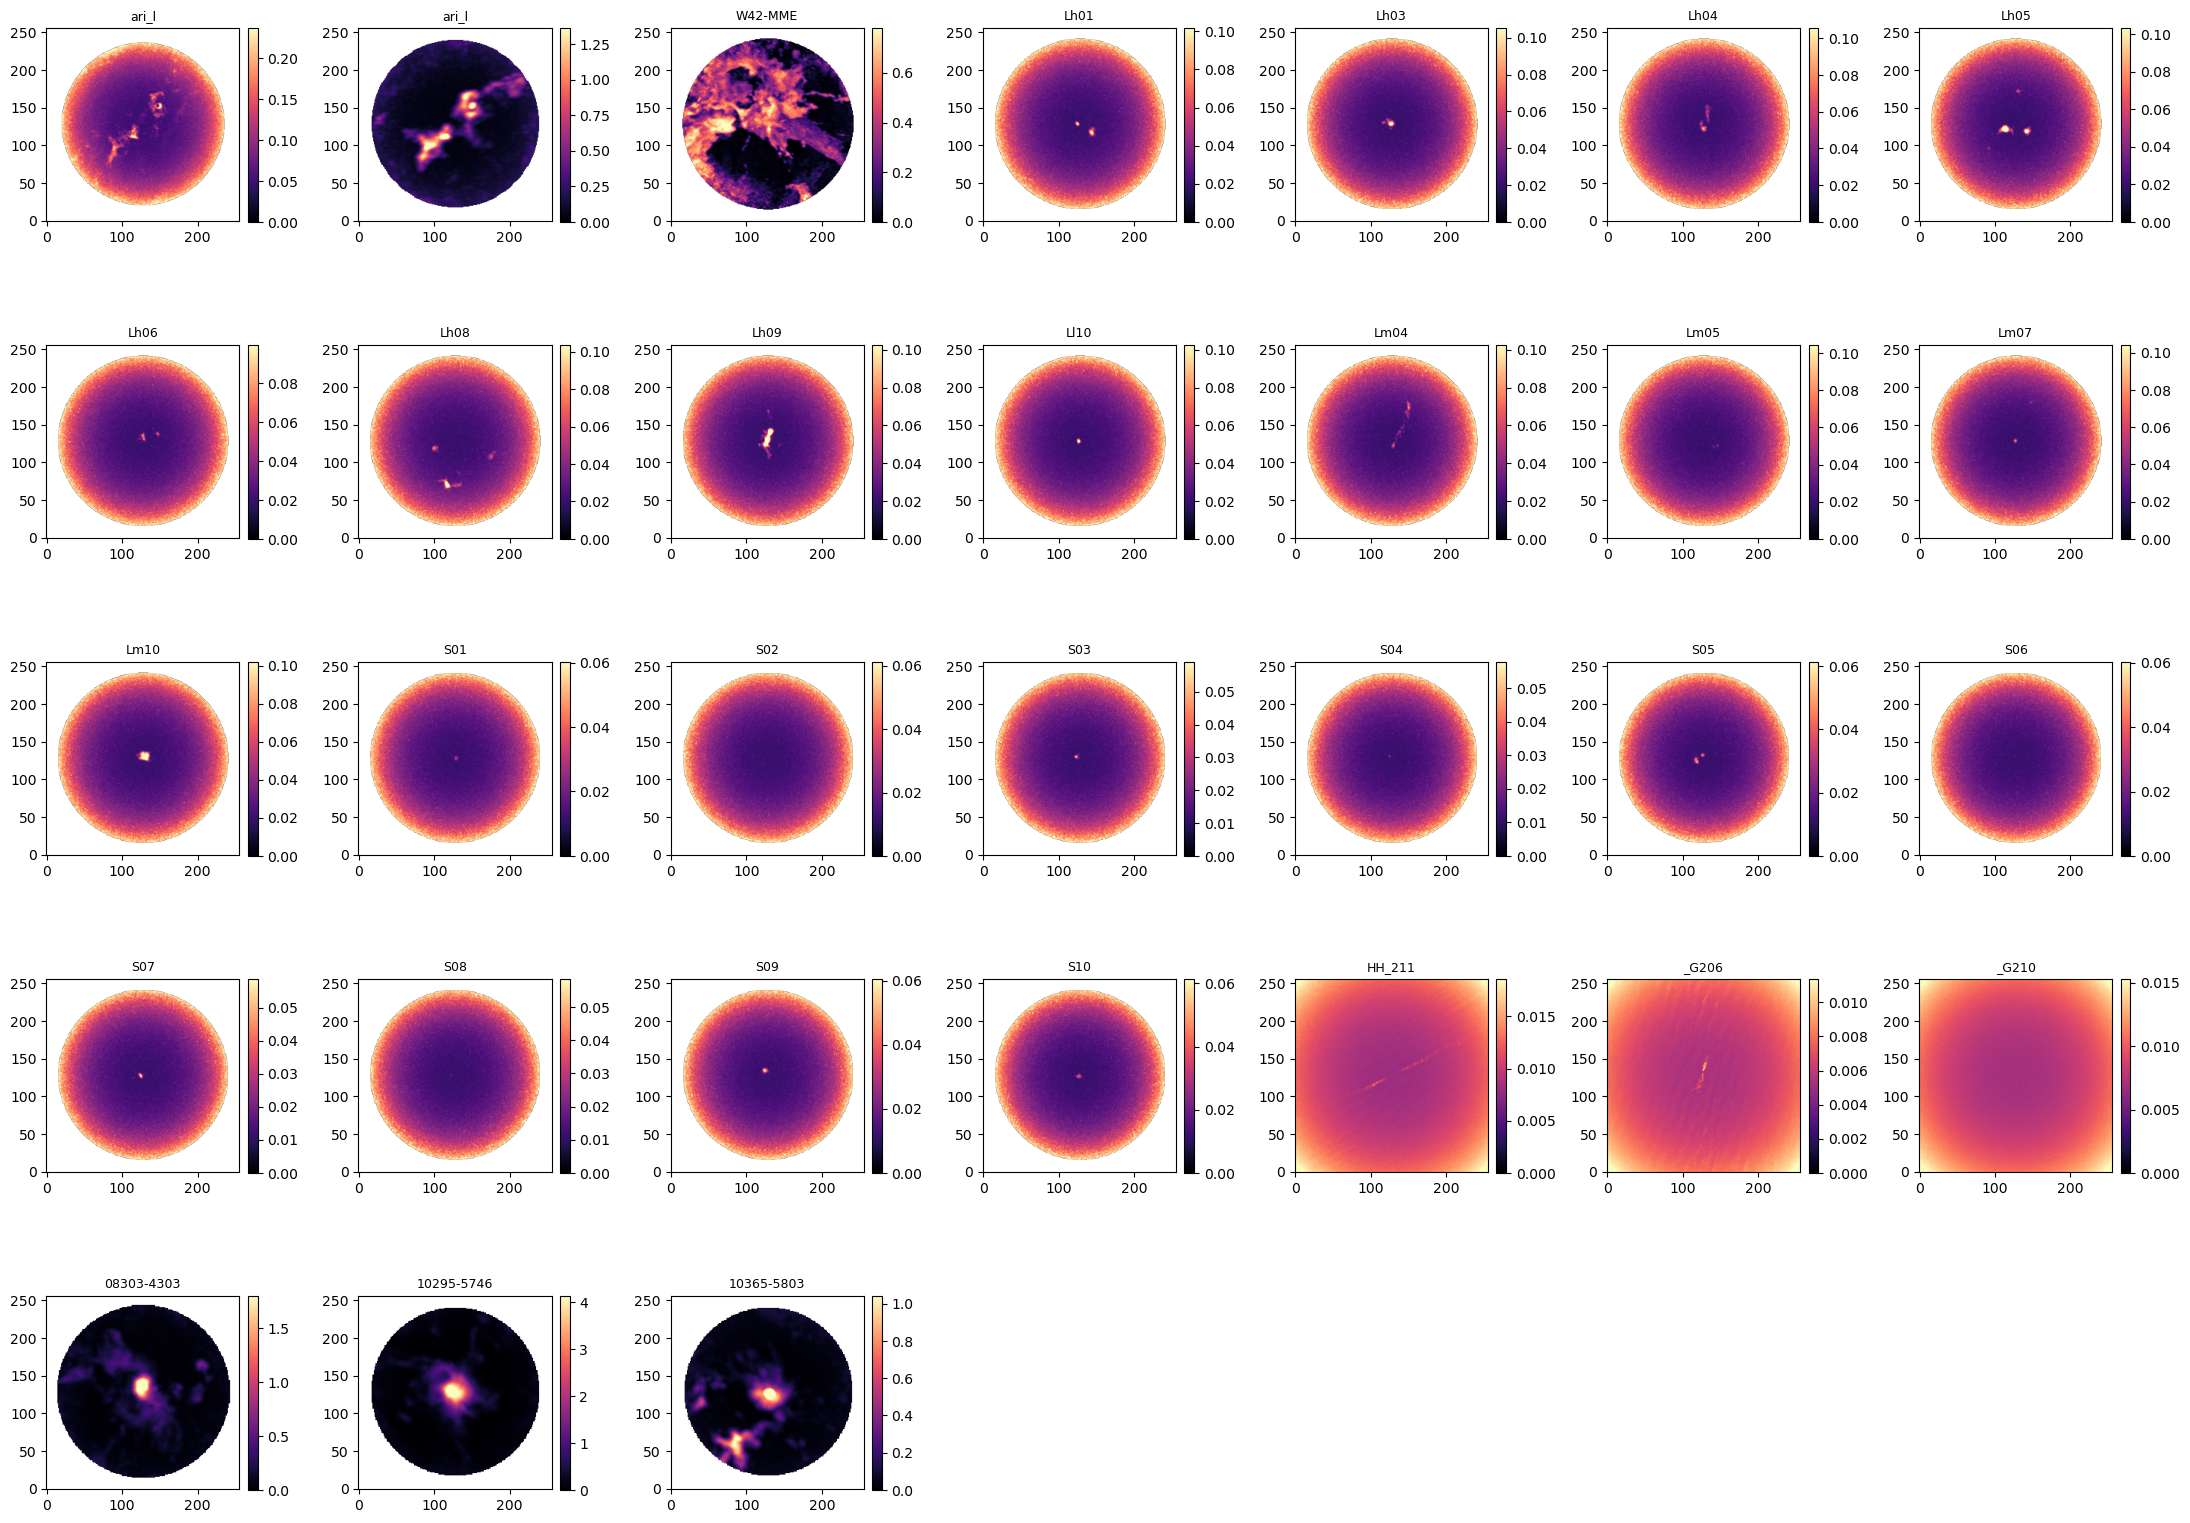

In [48]:
fig, axes = plt.subplots(5, 7, figsize=(22, 16))

names = list(resized_maps.keys())

for i, ax in enumerate(axes.flat):

    if i < len(names):

        name = names[i]
        data = resized_maps[name]

        # Extract source name
        source_name = name.split(".")[2].split("_sci")[0]

        # Plot resized moment-8 map
        im = ax.imshow(
            data,
            origin="lower",
            cmap="magma", 
            vmin = 0,
        vmax = np.nanpercentile(data, 99.5)
        )

        ax.set_title(source_name, fontsize=9)

        plt.colorbar(
            im,
            ax=ax,
            fraction=0.046,
            pad=0.04
        )
    else:
        # Completely remove unused panels
        fig.delaxes(ax)

    #ax.axis("off")

plt.tight_layout()
plt.show()

In [45]:

# Dictionary to store normalized maps
normalized_maps = {}

for name, resized_data in resized_maps.items():

    # Get corresponding RMS value
    rms = rms_values[name]

    # Normalize each map by its RMS
    if np.isfinite(rms) and rms > 0:

        normalized_data = resized_data / rms

        # Store normalized map
        normalized_maps[name] = normalized_data

        # Extract source name
        source_name = name.split(".")[2].split("_sci")[0]

        print(source_name, normalized_data.shape)

print("Total normalized maps:", len(normalized_maps))

ari_l (256, 256)
ari_l (256, 256)
W42-MME (256, 256)
Lh01 (256, 256)
Lh03 (256, 256)
Lh04 (256, 256)
Lh05 (256, 256)
Lh06 (256, 256)
Lh08 (256, 256)
Lh09 (256, 256)
Ll10 (256, 256)
Lm04 (256, 256)
Lm05 (256, 256)
Lm07 (256, 256)
Lm10 (256, 256)
S01 (256, 256)
S02 (256, 256)
S03 (256, 256)
S04 (256, 256)
S05 (256, 256)
S06 (256, 256)
S07 (256, 256)
S08 (256, 256)
S09 (256, 256)
S10 (256, 256)
HH_211 (256, 256)
_G206 (256, 256)
_G210 (256, 256)
08303-4303 (256, 256)
10295-5746 (256, 256)
10365-5803 (256, 256)
Total normalized maps: 31


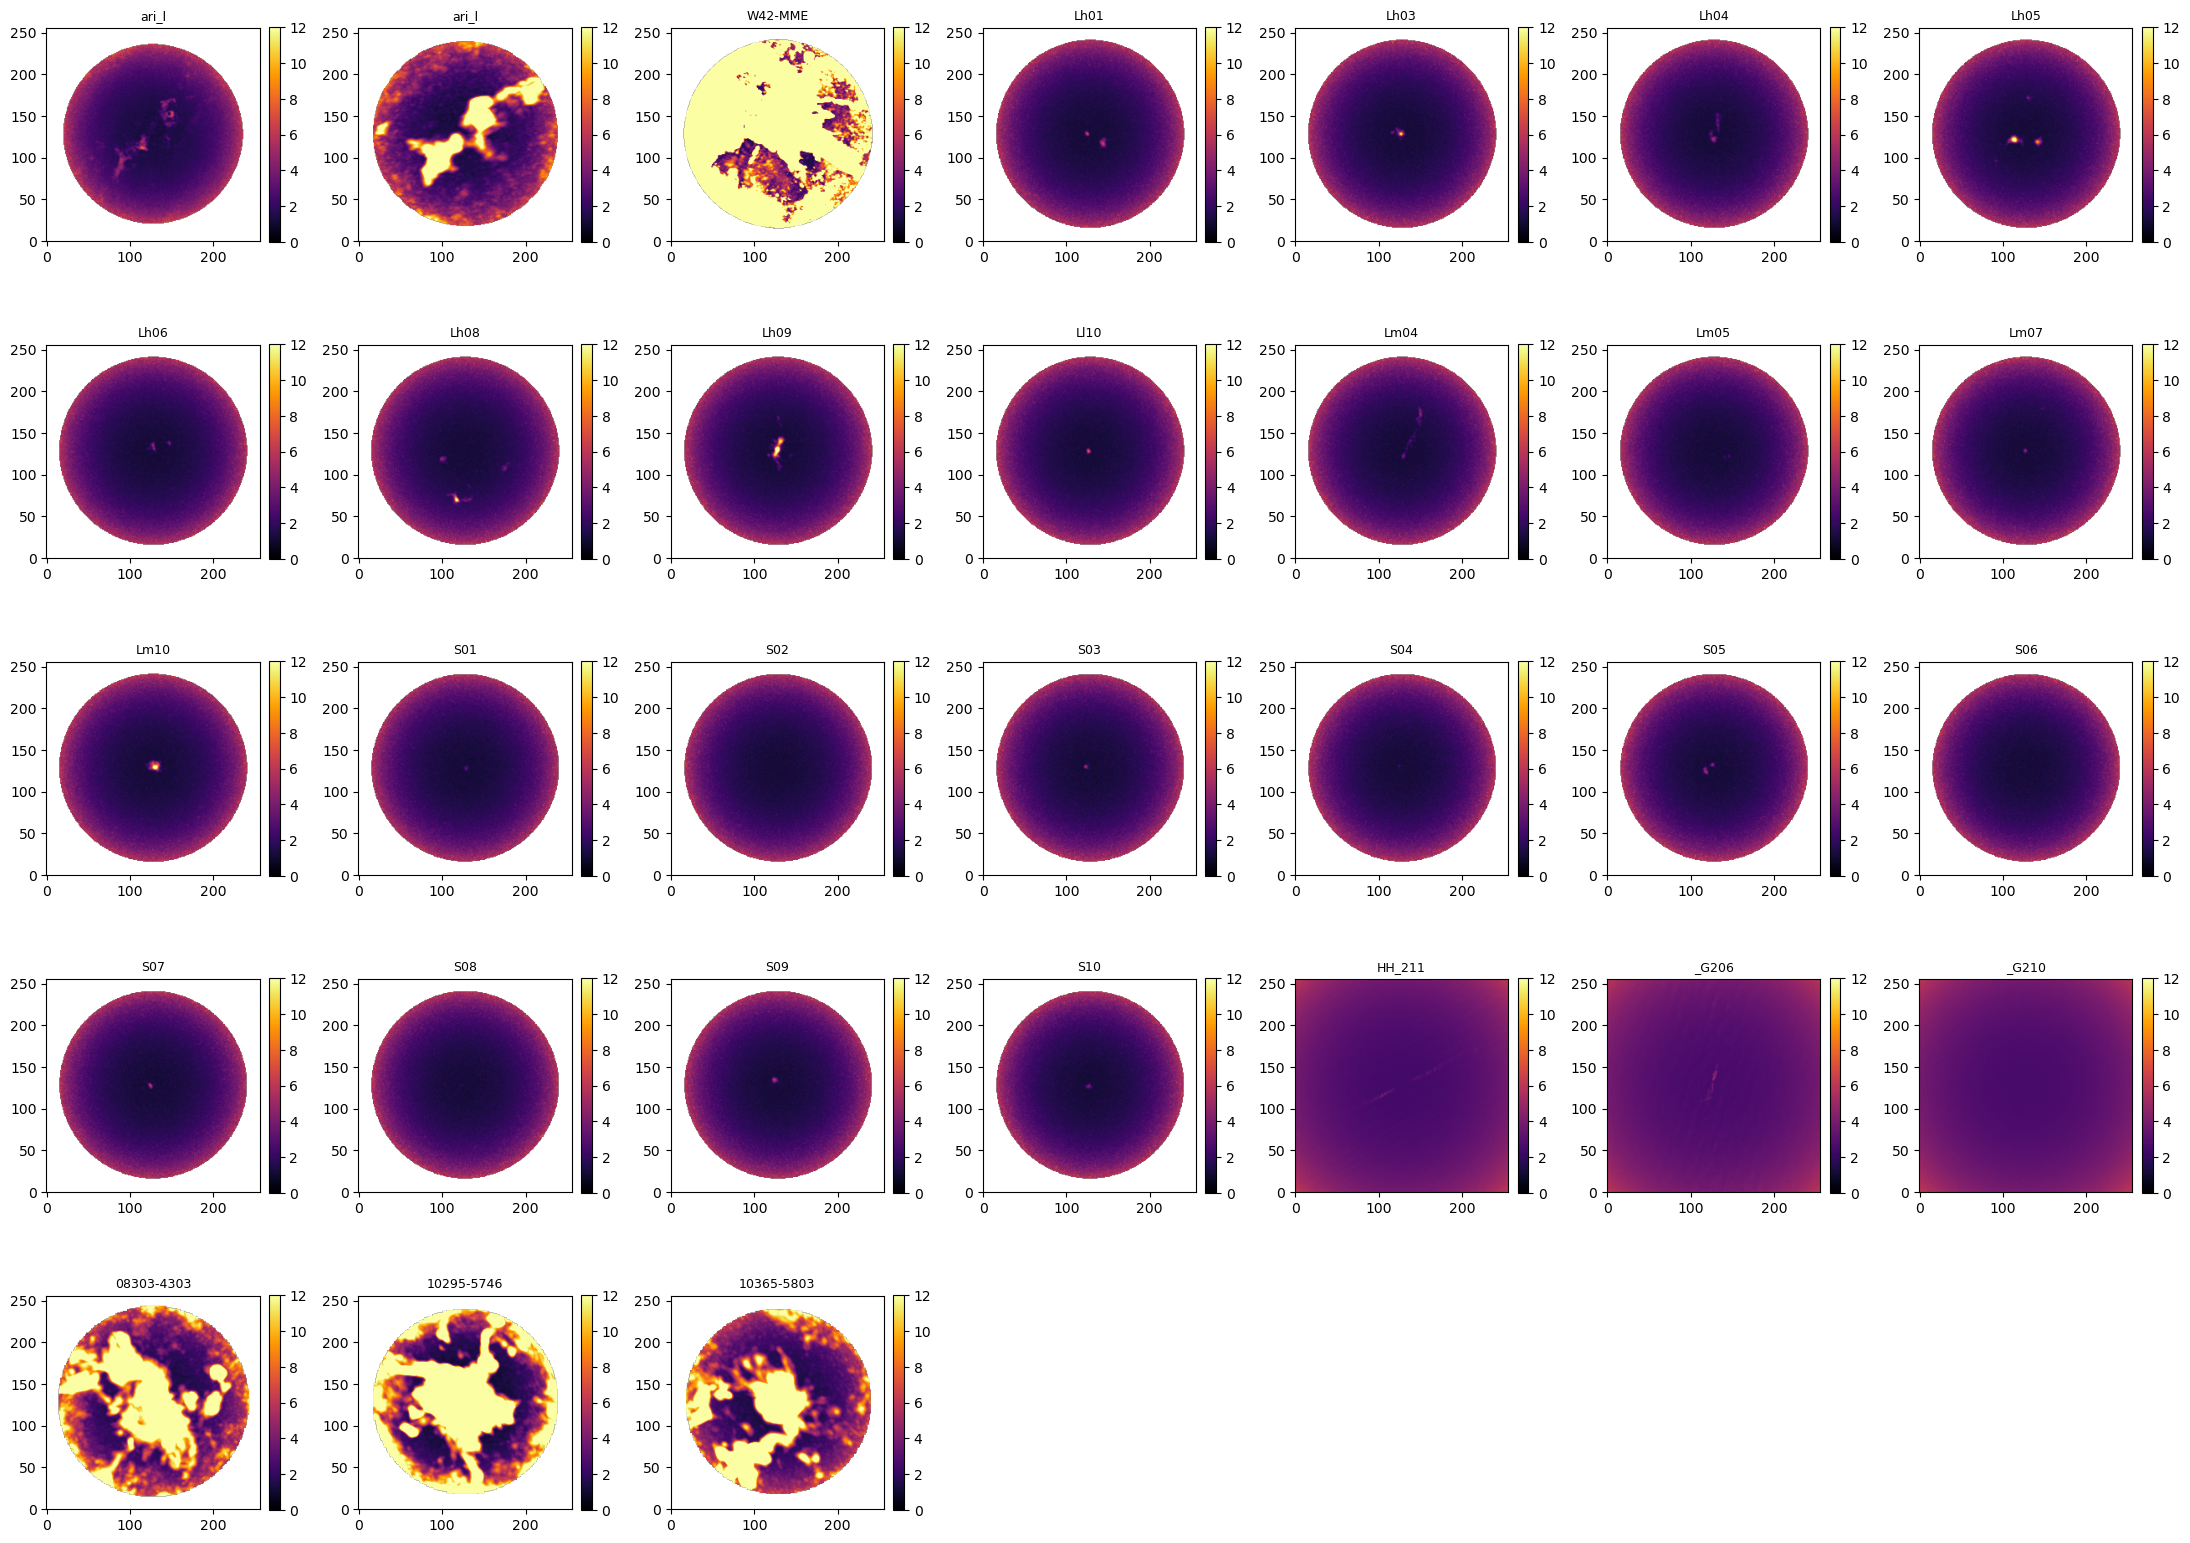

In [51]:

fig, axes = plt.subplots(5, 7, figsize= (22, 16))

names = list(normalized_maps.keys())

for i, ax in enumerate(axes.flat):

    if i < len(names):

        name = names[i]
        data = normalized_maps[name]

        source_name = name.split(".")[2].split("_sci")[0]

        im = ax.imshow(
            data,
            origin="lower",
            cmap="inferno",
            vmin=0,
            vmax=12)

        ax.set_title(source_name, fontsize=9)

        plt.colorbar(
            im,
            ax=ax,
            fraction=0.046,
            pad=0.04
        )
    else:
        # Completely remove unused panels
        fig.delaxes(ax)

    #ax.axis("off")

plt.tight_layout()
plt.show()

In [61]:

# Dictionary to store DBSCAN results
dbscan_maps = {}

for name, data in normalized_maps.items():

    # Select pixels above the threshold
    mask = np.isfinite(data) & (data > 5)

    # Get coordinates of selected pixels
    y, x = np.where(mask)

    # Combine x and y coordinates
    coordinates = np.column_stack((x, y))

    # Skip maps with no selected pixels
    if len(coordinates) == 0:
        print("No emission pixels:", name)
        continue

    # Run DBSCAN
    dbscan = DBSCAN(eps=5, min_samples=5)

    labels = dbscan.fit_predict(coordinates)

    # Create cluster map
    cluster_map = np.full(data.shape, -1, dtype=int)

    cluster_map[y, x] = labels

    # Store DBSCAN result
    dbscan_maps[name] = cluster_map

    # Count clusters
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

    # Extract source name
    source_name = name.split(".")[2].split("_sci")[0]

    print(f"{source_name}: Number of clusters = {n_clusters}")

print("Total DBSCAN maps:", len(dbscan_maps))

ari_l: Number of clusters = 4
ari_l: Number of clusters = 6
W42-MME: Number of clusters = 2
Lh01: Number of clusters = 3
Lh03: Number of clusters = 2
Lh04: Number of clusters = 1
Lh05: Number of clusters = 3
Lh06: Number of clusters = 1
Lh08: Number of clusters = 2
Lh09: Number of clusters = 2
Ll10: Number of clusters = 2
Lm04: Number of clusters = 1
Lm05: Number of clusters = 1
Lm07: Number of clusters = 1
Lm10: Number of clusters = 2
S01: Number of clusters = 1
S02: Number of clusters = 1
S03: Number of clusters = 1
S04: Number of clusters = 1
S05: Number of clusters = 1
S06: Number of clusters = 1
S07: Number of clusters = 2
S08: Number of clusters = 1
S09: Number of clusters = 2
S10: Number of clusters = 1
HH_211: Number of clusters = 4
_G206: Number of clusters = 4
_G210: Number of clusters = 4
08303-4303: Number of clusters = 3
10295-5746: Number of clusters = 5
10365-5803: Number of clusters = 5
Total DBSCAN maps: 31


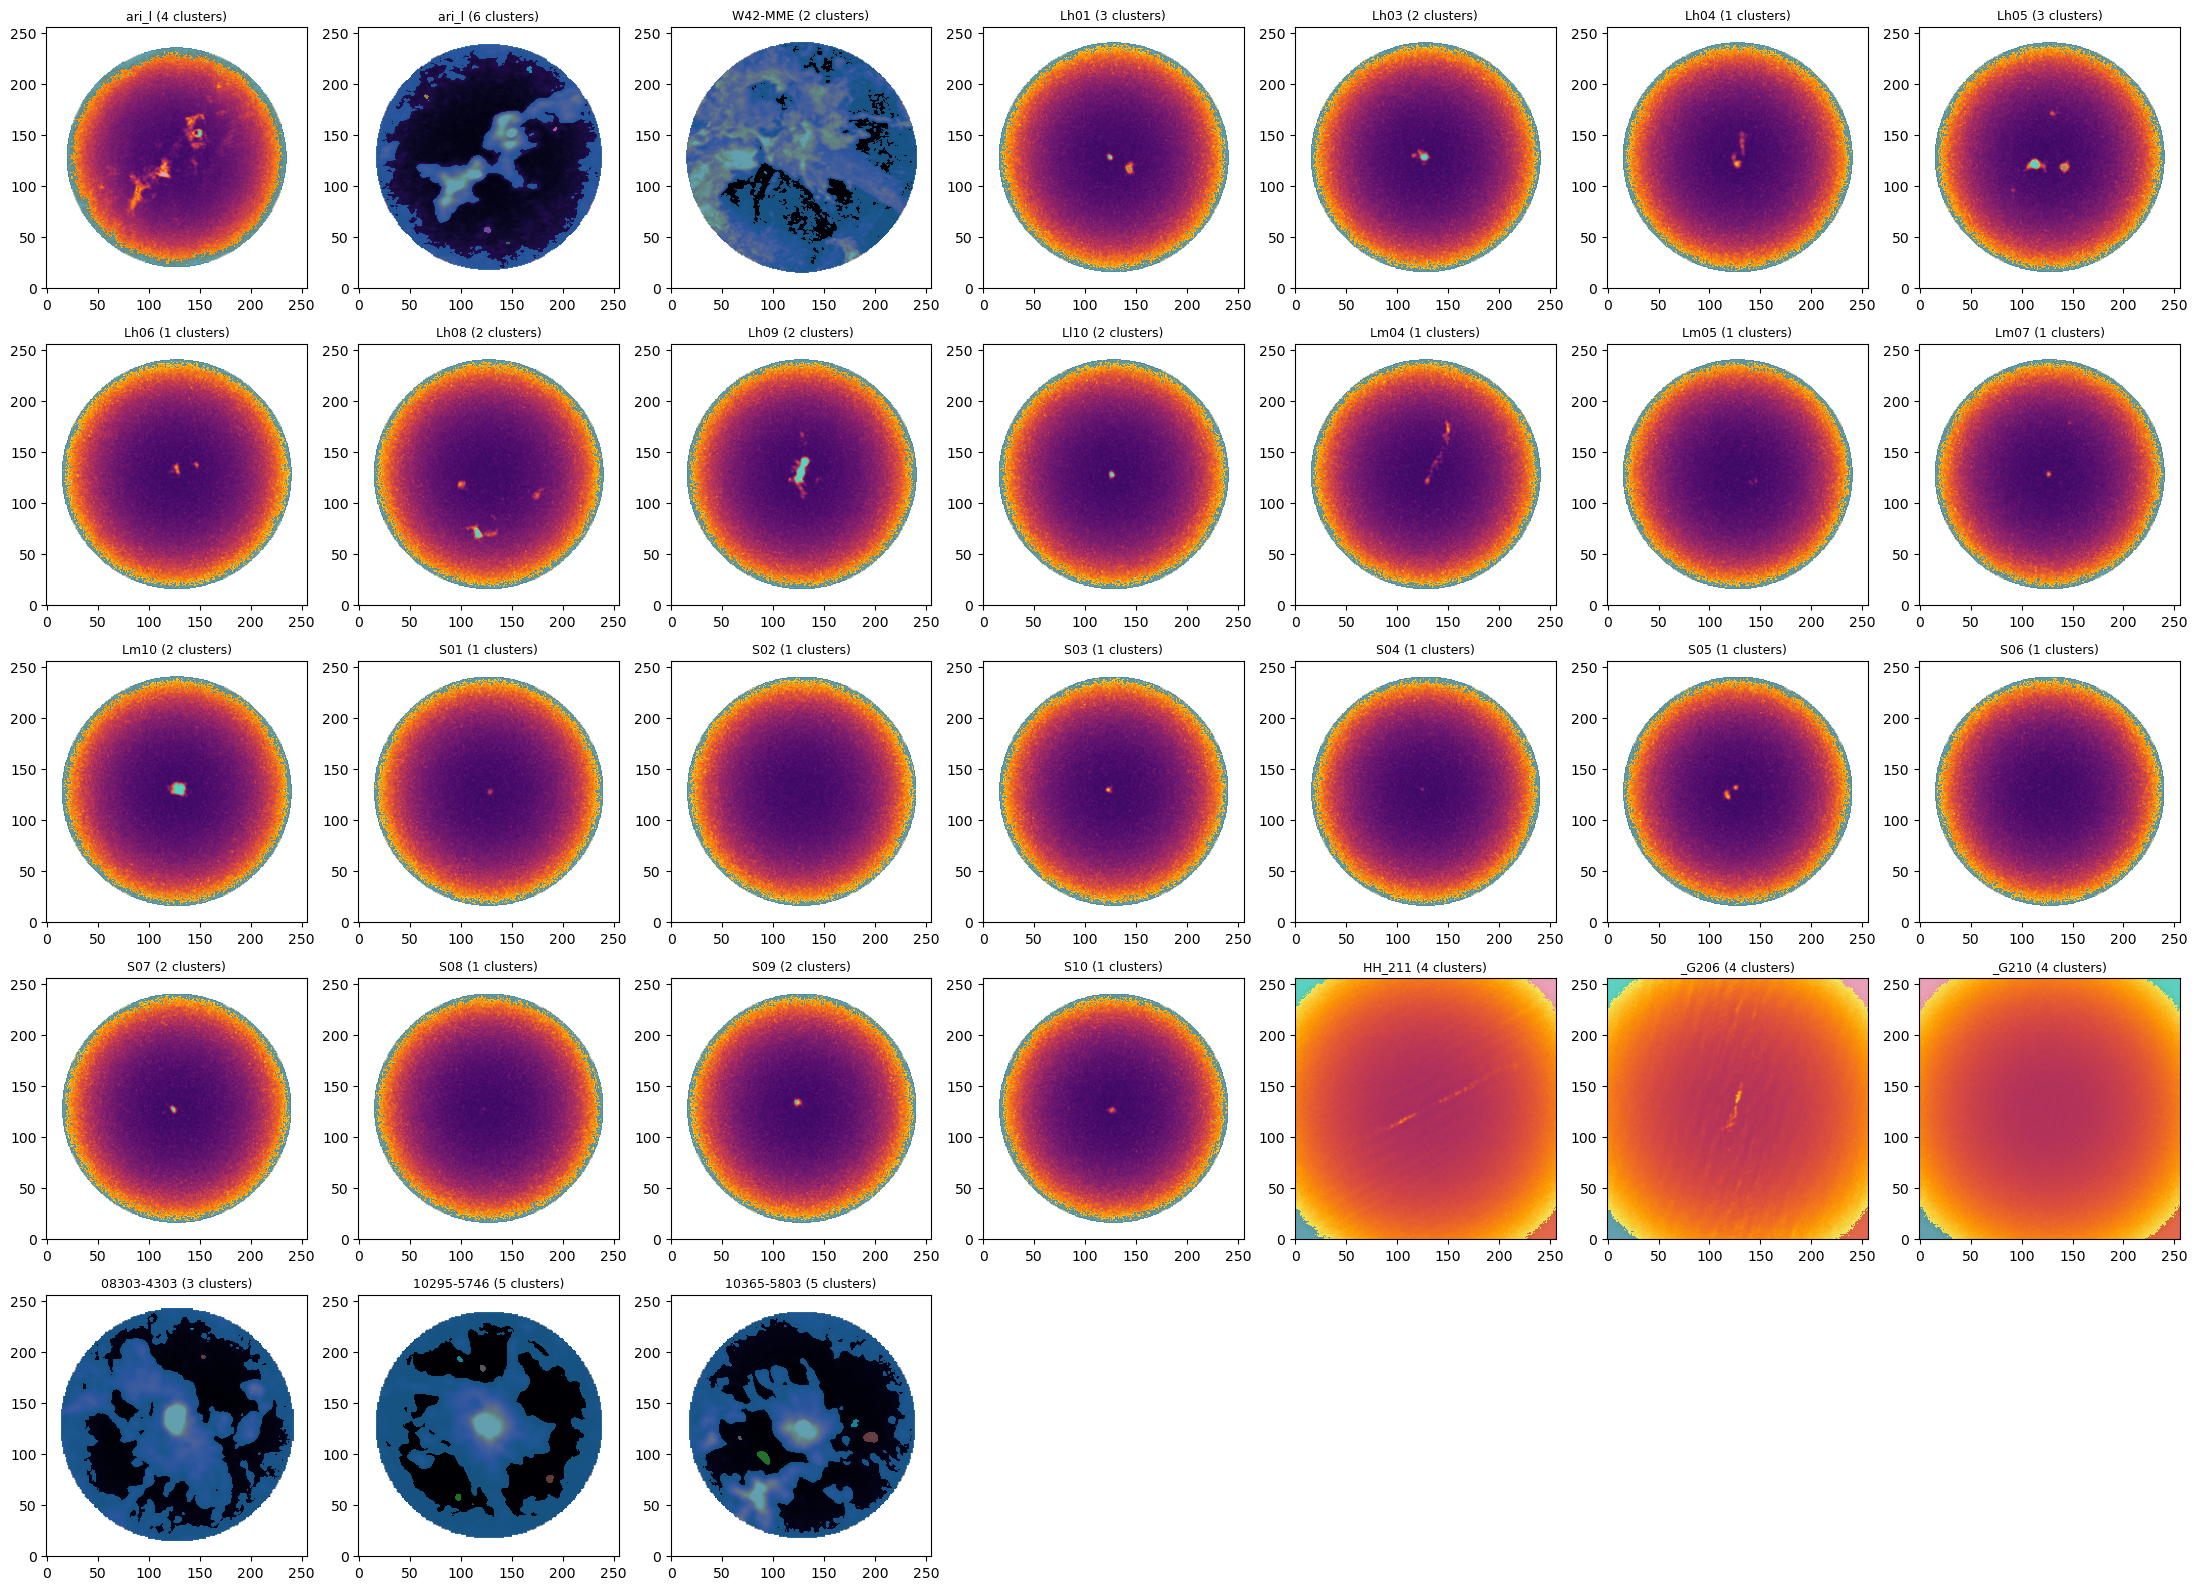

In [64]:

fig, axes = plt.subplots(5, 7, figsize=(22, 16))

names = list(dbscan_maps.keys())

for i, ax in enumerate(axes.flat):

    if i < len(names):

        name = names[i]

        data = normalized_maps[name]
        clusters = dbscan_maps[name]

        source_name = name.split(".")[2].split("_sci")[0]

        # Background: normalized moment-8 map
        vmax = np.nanpercentile(data, 99)

        ax.imshow(
            data,
            origin="lower",
            cmap="inferno",
            vmin=0,
            vmax=max(vmax, 1)
        )

        # Overlay DBSCAN clusters
        masked_clusters = np.ma.masked_where(
            clusters == -1,
            clusters
        )

        ax.imshow(
            masked_clusters,
            origin="lower",
            cmap="tab10",
            alpha=0.7,
            interpolation="nearest"
        )

        n_clusters = len(np.unique(clusters[clusters >= 0]))

        ax.set_title(
            f"{source_name} ({n_clusters} clusters)",
            fontsize=9
        )
    else:
        # Completely remove unused panels
        fig.delaxes(ax)

    #ax.axis("off")

plt.tight_layout()

plt.savefig(
    "DBSCAN_Overlay_Moment8.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()